Installment_payments.csv - aggregates for the last 2, 3, 5 payments. Aggregates over NUM_INSTALMENT_NUMBER at 1, 2, 3, 4 installments. Aggregates over last 60, 90, 180 & 365 days filtered on DAYS_INSTALMENT. I also did aggregates over all installments that were past due. Where past due was defined as a 1 if the difference between DAYS_ENTRY_PAYMENT and DAYS_INSTALMENT was positive and 0 if not.

https://www.kaggle.com/competitions/home-credit-default-risk/writeups/home-aloan-1st-place-solution

In [1]:
import numpy as np
import polars as pl
from polars import n_unique
from polars.functions.col import col
import re

import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from lightgbm import LGBMClassifier, early_stopping
import shap

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.inspection import permutation_importance # a way to measure feature importance for trained models
from sklearn.metrics import roc_auc_score

In [2]:
application_train = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/application_train.csv')
application_test = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/application_test.csv')
bureau = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/bureau.csv')
bureau_balance = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/bureau_balance.csv')
credit_card_balance = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/credit_card_balance.csv')
POS_CASH_balance = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/POS_CASH_balance.csv')
installments_payments = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/installments_payments.csv')
previous_application = pl.read_csv('/Users/alexzhang/Desktop/home-credit-default-risk/previous_application.csv')

In [3]:
# application_train.shape #307511, 122

# Bureau

In [4]:
bureau = bureau.join(bureau_balance, on="SK_ID_BUREAU", how="left")
# bureau['CREDIT_CURRENCY'].unique()

In [5]:
def unique_bureau_features(bureau: pl.DataFrame) -> pl.DataFrame:
    bureau = bureau.with_columns(
                                (pl.col('DAYS_CREDIT') >= -365).cast(pl.Int8).alias('BUREAU_CREDIT_LAST_365D'),
                                (pl.col('CREDIT_DAY_OVERDUE') > 0).cast(pl.Int8).alias('BUREAU_HAS_OVERDUE'),
                                (pl.col('AMT_CREDIT_SUM_OVERDUE').fill_null(0) > 0).cast(pl.Int8).alias('BUREAU_HAS_AMT_OVERDUE'),
                                (pl.col('CNT_CREDIT_PROLONG') > 0).cast(pl.Int8).alias('BUREAU_HAS_PROLONG'),
                                (pl.col('DAYS_CREDIT_ENDDATE') > 0).cast(pl.Int8).alias('BUREAU_ENDDATE_IN_FUTURE'),
                                (pl.col('DAYS_CREDIT_ENDDATE') - pl.col('DAYS_ENDDATE_FACT')).alias('credit_late_days')
                                )
    
    dummy_cols = ["CREDIT_ACTIVE", "CREDIT_TYPE", "STATUS", "CREDIT_CURRENCY"]
    bureau = bureau.to_dummies(columns=dummy_cols, separator="_")

    continuous_cols = [
        "DAYS_CREDIT",                     # days before current application the credit was granted
        "CREDIT_DAY_OVERDUE",              # overdue days
        "credit_late_days",                # late days calculated from end date and actual end date
        "CNT_CREDIT_PROLONG",              # number of prolongations 
        "AMT_CREDIT_MAX_OVERDUE",          # max overdue amount
        "AMT_CREDIT_SUM",                  # total credit amount
        "AMT_CREDIT_SUM_DEBT",             # current debt amount
        "AMT_CREDIT_SUM_LIMIT",            # credit limit
        "AMT_CREDIT_SUM_OVERDUE",          # overdue amount
        "DAYS_CREDIT_UPDATE",              # days since bureau record was updated
        "AMT_ANNUITY",                     # annuity amount
    ]
    flag_cols = [
        "BUREAU_CREDIT_LAST_365D",   # recent credit flag
        "BUREAU_HAS_OVERDUE",        # overdue flag
        "BUREAU_HAS_AMT_OVERDUE",    # overdue amount flag
        "BUREAU_HAS_PROLONG",        # prolong flag
        "BUREAU_ENDDATE_IN_FUTURE",  # future end date flag
    ]
    dummy_cols = [
        col for col in bureau.columns
        if col.startswith("CREDIT_ACTIVE_")
        or col.startswith("CREDIT_TYPE_")
        or col.startswith("STATUS_")
        or col.startswith("CREDIT_CURRENCY_")
    ]

    agg_exprs = []
    for col in continuous_cols:
        agg_exprs.extend([
            pl.col(col).mean().alias(f'{col}_mean'),
            pl.col(col).max().alias(f'{col}_max'),
        ])
    for col in flag_cols:
        agg_exprs.append(pl.col(col).sum().alias(f'{col}_max'))
    for col in dummy_cols:
        agg_exprs.append(pl.col(col).sum().alias(f'{col}_sum'))
    
    # how many bureau records are linked in a single application
    agg_exprs.extend([
    pl.col("SK_ID_BUREAU").count().alias("SK_ID_BUREAU_count"),
    pl.col("SK_ID_BUREAU").n_unique().alias("SK_ID_BUREAU_nunique"),
    ])

    bureau_features = bureau.group_by("SK_ID_CURR").agg(agg_exprs)
    return bureau_features

In [6]:
bureau_grouped = unique_bureau_features(bureau)
# bureau_grouped.head()
bureau_grouped.shape

(305811, 62)

# POS_CASH Balance

In [7]:
def poscashb_features(pos_cash_balance: pl.DataFrame) -> pl.DataFrame:
    """
    Aggregate POS_CASH_balance to SK_ID_CURR level.
    1. Overall mean/max aggregates for key continuous columns
    2. Sum of NAME_CONTRACT_STATUS dummy variables
    3. Overall delinquency count/ratio
    4. Dummy flags for whether SK_ID_CURR had delinquency in last
       60, 90, 180, 365 days
    """

    # 1. One-hot encode NAME_CONTRACT_STATUS
    pos_cash_balance = pos_cash_balance.to_dummies(
        columns=["NAME_CONTRACT_STATUS"],
        separator="_"
    )

    dummy_cols = [
        col for col in pos_cash_balance.columns
        if col.startswith("NAME_CONTRACT_STATUS_")
    ]

    # 2. Row-level delinquency flags
    # SK_DPD > 0 means days past due exists
    # SK_DPD_DEF > 0 is stricter: DPD with tolerance/definition
    pos_cash_balance = pos_cash_balance.with_columns([
        (pl.col("SK_DPD") > 0)
        .cast(pl.Int8)
        .alias("POS_HAS_DPD"),

        (pl.col("SK_DPD_DEF") > 0)
        .cast(pl.Int8)
        .alias("POS_HAS_DPD_DEF"),
    ])

    continuous_cols = [
        "MONTHS_BALANCE",
        "CNT_INSTALMENT",
        "CNT_INSTALMENT_FUTURE",
        "SK_DPD",
        "SK_DPD_DEF",
    ]

    agg_exprs = []
    # 3. Overall mean/max aggregates
    for col in continuous_cols:
        agg_exprs.extend([
            pl.col(col).mean().alias(f"{col}_mean"),
            pl.col(col).max().alias(f"{col}_max"),
        ])

    # 4. Contract status dummy sums
    for col in dummy_cols:
        agg_exprs.append(
            pl.col(col).sum().alias(f"{col}_sum")
        )

    # 5. Overall delinquency count/ratio
    agg_exprs.extend([
        pl.col("POS_HAS_DPD")
        .sum()
        .alias("POS_HAS_DPD_count"),

        pl.col("POS_HAS_DPD")
        .mean()
        .alias("POS_HAS_DPD_ratio"),

        pl.col("POS_HAS_DPD_DEF")
        .sum()
        .alias("POS_HAS_DPD_DEF_count"),

        pl.col("POS_HAS_DPD_DEF")
        .mean()
        .alias("POS_HAS_DPD_DEF_ratio"),
    ])

    # 6. Dummy flags for delinquency in last 60/90/180/365 days
    # MONTHS_BALANCE is in months relative to current application.
    day_to_month_windows = {
        60: 2,
        90: 3,
        180: 6,
        365: 12,
    }

    for days, months in day_to_month_windows.items():
        recent_condition = pl.col("MONTHS_BALANCE") >= -months

        dpd_recent_condition = (
            recent_condition
            & (pl.col("POS_HAS_DPD") == 1)
        )

        dpd_def_recent_condition = (
            recent_condition
            & (pl.col("POS_HAS_DPD_DEF") == 1)
        )

        # Broad delinquency flag:
        # 1 if this SK_ID_CURR had any POS DPD in the recent window
        agg_exprs.append(
            pl.when(dpd_recent_condition)
            .then(1)
            .otherwise(0)
            .max()
            .cast(pl.Int8)
            .alias(f"POS_HAS_DPD_LAST_{days}D")
        )

        # Stricter delinquency flag:
        # 1 if this SK_ID_CURR had any POS DPD_DEF in the recent window
        agg_exprs.append(
            pl.when(dpd_def_recent_condition)
            .then(1)
            .otherwise(0)
            .max()
            .cast(pl.Int8)
            .alias(f"POS_HAS_DPD_DEF_LAST_{days}D")
        )

    # 7. Final aggregation to SK_ID_CURR level
    poscashb_features = (
        pos_cash_balance
        .group_by("SK_ID_CURR")
        .agg(agg_exprs)
    )

    return poscashb_features

In [8]:
POS_CASH_balance = poscashb_features(POS_CASH_balance)
# POS_CASH_balance.head()
# POS_CASH_balance.shape #(337252, 20)

# instalments_payments

In [9]:
def installments_features(installments_payments: pl.DataFrame) -> pl.DataFrame:
    installments_payments = installments_payments.drop("NUM_INSTALMENT_VERSION")
    installments_payments = installments_payments.with_columns([
        (
            pl.col("DAYS_ENTRY_PAYMENT") - pl.col("DAYS_INSTALMENT")
        ).alias("PAYMENT_DELAY_DAYS"),

        (
            (pl.col("DAYS_ENTRY_PAYMENT") - pl.col("DAYS_INSTALMENT")) > 0
        )
        .cast(pl.Int8)
        .alias("INSTALLMENT_PAST_DUE"),
    ])

    continuous_cols = [
        "NUM_INSTALMENT_NUMBER",
        "DAYS_INSTALMENT",
        "DAYS_ENTRY_PAYMENT",
        "AMT_INSTALMENT",
        "AMT_PAYMENT",
        "PAYMENT_DELAY_DAYS",
    ]

    agg_exprs = []
    for col in continuous_cols:
        agg_exprs.extend([
            pl.col(col).mean().alias(f"{col}_mean"),
            pl.col(col).max().alias(f"{col}_max"),
        ])

    # Useful simple past-due features
    agg_exprs.extend([
        pl.col("INSTALLMENT_PAST_DUE")
        .sum()
        .alias("INSTALLMENT_PAST_DUE_count"),

        pl.col("INSTALLMENT_PAST_DUE")
        .mean()
        .alias("INSTALLMENT_PAST_DUE_ratio"),
    ])


    # Aggregates over NUM_INSTALMENT_NUMBER = 1, 2, 3, 4
    for num in [1, 2, 3, 4]:
        num_condition = pl.col("NUM_INSTALMENT_NUMBER") == num

        for col in continuous_cols:
            agg_exprs.extend([
                pl.col(col)
                .filter(num_condition)
                .mean()
                .alias(f"INSTALMENT_NUM_{num}_{col}_mean"),

                pl.col(col)
                .filter(num_condition)
                .max()
                .alias(f"INSTALMENT_NUM_{num}_{col}_max"),
            ])


    # Dummy flags for past-due in last 60/90/180/365 days
    for window in [60, 90, 180, 365]:
        past_due_recent_condition = (
            (pl.col("DAYS_INSTALMENT") >= -window)
            & (pl.col("INSTALLMENT_PAST_DUE") == 1)
        )

        agg_exprs.append(
            pl.when(past_due_recent_condition)
            .then(1)
            .otherwise(0)
            .max()
            .cast(pl.Int8)
            .alias(f"INSTALLMENTS_HAS_PAST_DUE_LAST_{window}D")
        )

    # Aggregates over all past-due installments
    past_due_condition = pl.col("INSTALLMENT_PAST_DUE") == 1

    for col in continuous_cols:
        agg_exprs.extend([
            pl.col(col)
            .filter(past_due_condition)
            .mean()
            .alias(f"PAST_DUE_{col}_mean"),

            pl.col(col)
            .filter(past_due_condition)
            .max()
            .alias(f"PAST_DUE_{col}_max"),
        ])

    # Final aggregation to one row per SK_ID_CURR
    installments_agg = (
        installments_payments
        .group_by("SK_ID_CURR")
        .agg(agg_exprs)
    )

    return installments_agg

In [10]:
installments_payments = installments_features(installments_payments)
# installments_payments.head()
# installments_payments.shape #339587, 15

# credit card balance

In [11]:
def creditcard_features(credit_card_balance: pl.DataFrame) -> pl.DataFrame:
    """
    Aggregate credit_card_balance to SK_ID_CURR level.

    Features:
    1. Overall mean/max aggregates for credit card numeric columns
    2. Sum/mean aggregates for simple 0/1 behavior flags
    3. Dummy flags for whether SK_ID_CURR had credit-card delinquency
       in last 60, 90, 180, 365 days
    """

    credit_card_balance = credit_card_balance.with_columns([
        (pl.col("SK_DPD") > 0)
        .cast(pl.Int8)
        .alias("CC_HAS_DPD"),

        (pl.col("SK_DPD_DEF") > 0)
        .cast(pl.Int8)
        .alias("CC_HAS_DPD_DEF"),

        (pl.col("AMT_BALANCE") > 0)
        .cast(pl.Int8)
        .alias("CC_HAS_BALANCE"),

        (
            pl.col("AMT_PAYMENT_TOTAL_CURRENT")
            .fill_null(0) > 0
        )
        .cast(pl.Int8)
        .alias("CC_HAS_PAYMENT"),
    ])

    continuous_cols = [
        "MONTHS_BALANCE",
        "AMT_BALANCE",
        "AMT_CREDIT_LIMIT_ACTUAL",
        "AMT_DRAWINGS_ATM_CURRENT",
        "AMT_DRAWINGS_CURRENT",
        "AMT_DRAWINGS_OTHER_CURRENT",
        "AMT_DRAWINGS_POS_CURRENT",
        "AMT_INST_MIN_REGULARITY",
        "AMT_PAYMENT_CURRENT",
        "AMT_PAYMENT_TOTAL_CURRENT",
        "AMT_RECEIVABLE_PRINCIPAL",
        "AMT_RECIVABLE",
        "AMT_TOTAL_RECEIVABLE",
        "CNT_DRAWINGS_ATM_CURRENT",
        "CNT_DRAWINGS_CURRENT",
        "CNT_DRAWINGS_OTHER_CURRENT",
        "CNT_DRAWINGS_POS_CURRENT",
        "CNT_INSTALMENT_MATURE_CUM",
        "SK_DPD",
        "SK_DPD_DEF",
    ]

    flag_cols = [
        "CC_HAS_DPD",
        "CC_HAS_DPD_DEF",
        "CC_HAS_BALANCE",
        "CC_HAS_PAYMENT",
    ]

    agg_exprs = []

    # 1. Overall mean/max aggregates
    for col in continuous_cols:
        agg_exprs.extend([
            pl.col(col).mean().alias(f"{col}_mean"),
            pl.col(col).max().alias(f"{col}_max"),
        ])

    # 2. Overall flag aggregates
    for col in flag_cols:
        agg_exprs.extend([
            pl.col(col).sum().alias(f"{col}_sum"),
            pl.col(col).mean().alias(f"{col}_mean"),
        ])

    # 3. Simple count features
    agg_exprs.extend([
        pl.col("MONTHS_BALANCE")
        .count()
        .alias("MONTHS_BALANCE_count"),

        pl.col("MONTHS_BALANCE")
        .max()
        .alias("MONTHS_BALANCE_max2"),
    ])

    # 4. Recent delinquency dummy flags
    # MONTHS_BALANCE is monthly, so convert day windows to month windows.
    day_to_month_windows = {
        60: 2,
        90: 3,
        180: 6,
        365: 12,
    }

    for days, months in day_to_month_windows.items():
        recent_condition = pl.col("MONTHS_BALANCE") >= -months

        dpd_recent_condition = (
            recent_condition
            & (pl.col("CC_HAS_DPD") == 1)
        )

        dpd_def_recent_condition = (
            recent_condition
            & (pl.col("CC_HAS_DPD_DEF") == 1)
        )

        agg_exprs.extend([
            pl.when(dpd_recent_condition)
            .then(1)
            .otherwise(0)
            .max()
            .cast(pl.Int8)
            .alias(f"CC_HAS_DPD_LAST_{days}D"),

            pl.when(dpd_def_recent_condition)
            .then(1)
            .otherwise(0)
            .max()
            .cast(pl.Int8)
            .alias(f"CC_HAS_DPD_DEF_LAST_{days}D"),
        ])

    features = (
        credit_card_balance
        .group_by("SK_ID_CURR")
        .agg(agg_exprs)
    )

    return features

In [12]:
credit_card_balance = creditcard_features(credit_card_balance)
# credit_card_balance.head()
credit_card_balance.shape

(103558, 59)

# Previous application

In [13]:
def top3prevapp(previous_application: pl.DataFrame) -> pl.DataFrame:
    previous_application = previous_application.sort(
        ["SK_ID_CURR", "DAYS_DECISION"],
        descending=[False, True]
    )

    previous_application = previous_application.with_columns(
        (
            pl.int_range(pl.len())
            .over("SK_ID_CURR") + 1
        ).alias("_rank")
    )

    previous_application = previous_application.filter(
        pl.col("_rank") <= 3
    )

    value_cols = [
        col for col in previous_application.columns
        if col not in ["SK_ID_CURR", "_rank"]
    ]

    wide_parts = []

    for r in [1, 2, 3]:
        part = (
            previous_application
            .filter(pl.col("_rank") == r)
            .select(["SK_ID_CURR"] + value_cols)
            .rename({col: f"{col}_prev{r}" for col in value_cols})
        )

        wide_parts.append(part)

    prev_wide = wide_parts[0]

    for part in wide_parts[1:]:
        prev_wide = prev_wide.join(
            part,
            on="SK_ID_CURR",
            how="left"
        )

    return prev_wide

In [14]:
previous_application = top3prevapp(previous_application)
# previous_application.head()
previous_application.shape

(338857, 109)

# Combination: we must get the datasets updated before processing this function

allow us to get updated training and testing dataset

In [15]:
def combination(
    application_train: pl.DataFrame, 
    previous_application: pl.DataFrame, 
    bureau_grouped: pl.DataFrame, 
    POS_CASH_balance: pl.DataFrame, 
    installments_payments: pl.DataFrame, 
    credit_card_balance: pl.DataFrame
) -> pl.DataFrame:
    application_train = application_train.join(previous_application, on="SK_ID_CURR", how="left")\
        .join(bureau_grouped, on="SK_ID_CURR", how="left")\
        .join(POS_CASH_balance, on="SK_ID_CURR", how="left")\
        .join(installments_payments, on="SK_ID_CURR", how="left")\
        .join(credit_card_balance, on="SK_ID_CURR", how="left")
    return application_train

In [16]:
application_train = combination(application_train, 
                                previous_application, 
                                bureau_grouped, 
                                POS_CASH_balance, 
                                installments_payments, 
                                credit_card_balance)
application_test = combination(application_test, 
                                previous_application, 
                                bureau_grouped, 
                                POS_CASH_balance, 
                                installments_payments, 
                                credit_card_balance)

# Feature engineering

In [17]:
def feature_engineering(
    train: pl.DataFrame, 
    test: pl.DataFrame, 
    target_col: str = "TARGET",
    max_unique_for_dummies: int = 10,
    fill_numeric_nulls_with_zero: bool = True
):
    y = train[target_col]
    train = train.drop(target_col)

    train = train.with_columns(pl.lit(1).alias("is_train"))
    test = test.with_columns(pl.lit(0).alias("is_train"))

    full = pl.concat([train, test], how="vertical")

    # 1. row-level application features
    new_exprs = []

    if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(set(full.columns)):
        new_exprs.append(
            (
                pl.col("AMT_CREDIT") / (pl.col("AMT_ANNUITY") + 1e-6)
            ).alias("credit_annuity_ratio")
        )

    if {"AMT_CREDIT", "AMT_GOODS_PRICE"}.issubset(set(full.columns)):
        new_exprs.append(
            (
                pl.col("AMT_CREDIT") / (pl.col("AMT_GOODS_PRICE") + 1e-6)
            ).alias("credit_goods_price_ratio")
        )

    if {"AMT_GOODS_PRICE", "AMT_CREDIT"}.issubset(set(full.columns)):
        new_exprs.append(
            (
                pl.col("AMT_GOODS_PRICE") - pl.col("AMT_CREDIT")
            ).alias("credit_downpayment")
        )

    if "DAYS_BIRTH" in full.columns:
        new_exprs.append(
            (
                pl.col("DAYS_BIRTH") / -365
            )
            .floor()
            .cast(pl.Int16)
            .alias("AGE_INT")
        )

    if {"AMT_ANNUITY", "AMT_INSTALMENT_max"}.issubset(set(full.columns)):
        new_exprs.append(
            (
                pl.col("AMT_ANNUITY") / (pl.col("AMT_INSTALMENT_max") + 1e-6)
            ).alias("annuity_to_max_installment_ratio")
        )

    if len(new_exprs) > 0:
        full = full.with_columns(new_exprs)


    # 2. Fix delinquency dummy columns after merging
    # After left joins, missing historical records create nulls.
    # For these dummy flags, null should become 0.
    delinquency_dummy_cols = [
        col for col in full.columns
        if (
            col.startswith("POS_HAS_DPD_LAST_")
            or col.startswith("POS_HAS_DPD_DEF_LAST_")
            or col.startswith("INSTALLMENTS_HAS_PAST_DUE_LAST_")
            or col.startswith("CC_HAS_DPD_LAST_")
            or col.startswith("CC_HAS_DPD_DEF_LAST_")
        )
    ]

    if len(delinquency_dummy_cols) > 0:
        full = full.with_columns([
            pl.col(col)
            .fill_null(0)
            .cast(pl.Int8)
            .alias(col)
            for col in delinquency_dummy_cols
        ])


    # 3. Treat REGION_ID_POPULATION as categorical
    if "REGION_ID_POPULATION" in full.columns:
        full = full.with_columns(
            pl.col("REGION_ID_POPULATION")
            .cast(pl.String)
            .alias("region_id")
        )

        full = full.drop("REGION_ID_POPULATION")


    # 4. Convert boolean columns to Int8
    bool_cols = [
        col for col, dtype in full.schema.items()
        if dtype == pl.Boolean
    ]

    if len(bool_cols) > 0:
        full = full.with_columns([
            pl.col(col).cast(pl.Int8).alias(col)
            for col in bool_cols
            if col != "is_train"
        ])


    # 5. fill all numeric nulls with 0
    if fill_numeric_nulls_with_zero:
        numeric_cols = [
            col for col, dtype in full.schema.items()
            if dtype in [
                pl.Int8, pl.Int16, pl.Int32, pl.Int64,
                pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64,
                pl.Float32, pl.Float64
            ]
            and col != "is_train"
        ]

        if len(numeric_cols) > 0:
            full = full.with_columns([
                pl.col(col).fill_null(0).alias(col)
                for col in numeric_cols
            ])

    # 6. Drop constant columns
    const_cols = [
        col for col in full.columns
        if full[col].n_unique() <= 1
    ]

    if len(const_cols) > 0:
        full = full.drop(const_cols)

    # 7. Categorical encoding
    id_cols = [
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "SK_ID_PREV",
        "SK_ID_CURR_prev1",
        "SK_ID_CURR_prev2",
        "SK_ID_CURR_prev3",
        "SK_ID_PREV_prev1",
        "SK_ID_PREV_prev2",
        "SK_ID_PREV_prev3",
    ]

    cat_cols = [
        col for col, dtype in full.schema.items()
        if dtype in [pl.Utf8, pl.Categorical, pl.Enum]
        and col not in id_cols
    ]

    binary_cols = []
    one_hot_cols = []
    left_as_is_cols = []

    for col in cat_cols:
        standardized = (
            full[col]
            .drop_nulls()
            .cast(pl.String)
            .str.strip_chars()
        )

        unique_vals = standardized.unique().to_list()
        n_unique = len(unique_vals)

        if n_unique == 2:
            mapping = {
                unique_vals[0]: 0,
                unique_vals[1]: 1
            }

            full = full.with_columns(
                pl.col(col)
                .cast(pl.String)
                .str.strip_chars()
                .replace(mapping)
                .cast(pl.Int8)
                .alias(col)
            )

            binary_cols.append(col)

        elif 3 <= n_unique <= max_unique_for_dummies:
            one_hot_cols.append(col)

        else:
            left_as_is_cols.append(col)

    if len(one_hot_cols) > 0:
        full = full.to_dummies(
            columns=one_hot_cols,
            separator="_"
        )

    # 8. Split back into train/test
    train_processed = (
        full
        .filter(pl.col("is_train") == 1)
        .drop("is_train")
    )

    test_processed = (
        full
        .filter(pl.col("is_train") == 0)
        .drop("is_train")
    )

    train_processed = train_processed.with_columns(
        y.alias(target_col)
    )

    return train_processed, test_processed

In [18]:
train_processed, test_processed = feature_engineering(application_train, application_test)

In [19]:
def clean_feature_names(df: pl.DataFrame) -> pl.DataFrame:
    """
    Clean Polars column names for LightGBM.

    Fixes issues like:
    [LightGBM] [Fatal] Do not support special JSON characters in feature name.

    It replaces problematic characters with underscores and guarantees
    unique column names.
    """

    new_cols = []

    for c in df.columns:
        col = str(c)

        # Replace common JSON/problematic characters
        col = re.sub(r'[\[\]\{\}\"\,\:]', "_", col)

        # Replace anything not letter/number/underscore with underscore
        col = re.sub(r"[^A-Za-z0-9_]+", "_", col)

        # Collapse repeated underscores
        col = re.sub(r"_+", "_", col)

        # Remove leading/trailing underscores
        col = col.strip("_")

        # Avoid empty column names
        if col == "":
            col = "feature"

        new_cols.append(col)

    # Make column names unique after cleaning
    counts = {}
    unique_cols = []

    for col in new_cols:
        if col not in counts:
            counts[col] = 0
            unique_cols.append(col)
        else:
            counts[col] += 1
            unique_cols.append(f"{col}_{counts[col]}")

    rename_map = dict(zip(df.columns, unique_cols))

    return df.rename(rename_map)

In [20]:
application_train = clean_feature_names(train_processed)
application_test = clean_feature_names(test_processed)

# Train test split & vali

In [21]:
def train_test_split(
    X: pl.DataFrame,
    y: pl.Series,
    test_size: float = 0.2,
    random_state: int = 42
) -> tuple[pl.DataFrame, pl.DataFrame, pl.Series, pl.Series]:

    train_ids = (
        X.select("SK_ID_CURR")
        .sample(fraction=1 - test_size, seed=random_state)
        .get_column("SK_ID_CURR")
    )

    x_train = X.filter(pl.col("SK_ID_CURR").is_in(train_ids.to_list()))
    x_test = X.filter(~pl.col("SK_ID_CURR").is_in(train_ids.to_list()))

    y_df = pl.DataFrame({
        "SK_ID_CURR": X["SK_ID_CURR"],
        "TARGET": y
    })

    y_train = (
        y_df
        .filter(pl.col("SK_ID_CURR").is_in(train_ids.to_list()))
        .get_column("TARGET")
    )

    y_test = (
        y_df
        .filter(~pl.col("SK_ID_CURR").is_in(train_ids.to_list()))
        .get_column("TARGET")
    )

    return x_train, x_test, y_train, y_test

In [22]:
x = train_processed.drop("TARGET")
y = train_processed["TARGET"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

print("pos:", pos, "neg:", neg, "scale_pos_weight:", scale_pos_weight)

x_tr, x_val, y_tr, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.20,
    random_state=42
)

pos: 19904 neg: 226104 scale_pos_weight: 11.359726688102894


# LightGBM

In [23]:
# 1) Polars -> pandas
x_tr_pd = x_tr.to_pandas()
x_val_pd = x_val.to_pandas()
x_test_pd = x_test.to_pandas()

y_tr_pd = y_tr.to_pandas()
y_val_pd = y_val.to_pandas()
y_test_pd = y_test.to_pandas()

# 2) fix dtypes without importing pandas
# columns that should be numeric
numeric_like_cols = [
    "AMT_ANNUITY_max",
]

for col in numeric_like_cols:
    if col in x_tr_pd.columns:
        x_tr_pd[col] = x_tr_pd[col].astype("float64")
        x_val_pd[col] = x_val_pd[col].astype("float64")
        x_test_pd[col] = x_test_pd[col].astype("float64")

# columns that should be categorical
cat_cols = [
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_CASH_LOAN_PURPOSE_prev1",
    "NAME_GOODS_CATEGORY_prev1",
    "NAME_SELLER_INDUSTRY_prev1",
    "PRODUCT_COMBINATION_prev1",
    "NAME_CASH_LOAN_PURPOSE_prev2",
    "NAME_GOODS_CATEGORY_prev2",
    "NAME_SELLER_INDUSTRY_prev2",
    "PRODUCT_COMBINATION_prev2",
    "NAME_CASH_LOAN_PURPOSE_prev3",
    "NAME_GOODS_CATEGORY_prev3",
    "NAME_SELLER_INDUSTRY_prev3",
    "PRODUCT_COMBINATION_prev3",
]

for col in cat_cols:
    if col in x_tr_pd.columns:
        x_tr_pd[col] = x_tr_pd[col].astype("category")
        x_val_pd[col] = x_val_pd[col].astype("category")
        x_test_pd[col] = x_test_pd[col].astype("category")

print("Remaining object columns:")
print(x_tr_pd.columns[x_tr_pd.dtypes == "object"].tolist())

Remaining object columns:
[]


In [24]:
def clean_lgbm_column_names(columns):
    clean_cols = []

    for col in columns:
        col = str(col)

        # Replace LightGBM JSON-problem characters
        col = re.sub(r'[\[\]\{\}\"\,\:]', "_", col)

        # Replace all other non-safe characters with underscore
        col = re.sub(r"[^A-Za-z0-9_]+", "_", col)

        # Collapse repeated underscores
        col = re.sub(r"_+", "_", col)

        # Remove leading/trailing underscores
        col = col.strip("_")

        if col == "":
            col = "feature"

        clean_cols.append(col)

    # Make names unique
    seen = {}
    final_cols = []

    for col in clean_cols:
        if col not in seen:
            seen[col] = 0
            final_cols.append(col)
        else:
            seen[col] += 1
            final_cols.append(f"{col}_{seen[col]}")

    return final_cols


# Clean pandas feature names directly before LightGBM
clean_cols = clean_lgbm_column_names(x_tr_pd.columns)

x_tr_pd.columns = clean_cols
x_val_pd.columns = clean_cols
x_test_pd.columns = clean_cols

# Check if any bad characters remain
bad_cols = [
    col for col in x_tr_pd.columns
    if re.search(r'[\[\]\{\}\"\,\:]', str(col))
]

print("Bad LightGBM feature names remaining:")
print(bad_cols[:50])
print("Number of bad columns:", len(bad_cols))

# Check duplicate columns
print("Number of columns:", len(x_tr_pd.columns))
print("Number of unique columns:", len(set(x_tr_pd.columns)))

Bad LightGBM feature names remaining:
[]
Number of bad columns: 0
Number of columns: 691
Number of unique columns: 691


In [25]:
# define LightGBM model
lgbm = LGBMClassifier(
    objective="binary",
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    min_split_gain=0.0,
    min_child_weight=1e-3,
    subsample_freq=1,
    verbose=-1
)

param_grid = {
    "max_depth": [6, 8, 10], #tried 6, 7, 8, 10
    "num_leaves": [64, 128, 256], # 64, 256
    "min_child_samples": [20, 50, 80], #50, 20
    "n_estimators": [1000],
    "learning_rate": [0.1],
}

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=7
)

grid = GridSearchCV(
    estimator=lgbm,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    refit=True,
    n_jobs=-1,
    verbose=0
)

# 4) grid search
grid.fit(
    x_tr_pd,
    y_tr_pd,
    categorical_feature="auto"
)

print("Best parameters found:", grid.best_params_)
print("Best CV AUC:", grid.best_score_)

# 5) fit best model
lgb_best = LGBMClassifier(
    objective="binary",
    random_state=42,
    n_jobs=1,
    scale_pos_weight=scale_pos_weight,
    min_split_gain=0.0,
    min_child_weight=1e-3,
    subsample_freq=1,
    verbose=-1,
    **grid.best_params_
)

lgb_best.fit(
    x_tr_pd,
    y_tr_pd,
    eval_set=[(x_val_pd, y_val_pd)],
    eval_metric="auc",
    categorical_feature="auto",
    callbacks=[         
        early_stopping(
            stopping_rounds=20,
            min_delta=1e-4,
            verbose=False
        )
    ]
)

# 6) compare AUC
y_tr_proba = lgb_best.predict_proba(x_tr_pd)[:, 1]
y_val_proba = lgb_best.predict_proba(x_val_pd)[:, 1]
y_test_proba = lgb_best.predict_proba(x_test_pd)[:, 1]

train_roc_auc = roc_auc_score(y_tr_pd, y_tr_proba)
val_roc_auc = roc_auc_score(y_val_pd, y_val_proba)
test_roc_auc = roc_auc_score(y_test_pd, y_test_proba)

print(f"Train ROC-AUC: {train_roc_auc:.6f}")
print(f"Val   ROC-AUC: {val_roc_auc:.6f}")
print(f"Test  ROC-AUC: {test_roc_auc:.6f}")
print(f"Train - Val gap : {train_roc_auc - val_roc_auc:.6f}")
print(f"Train - Test gap: {train_roc_auc - test_roc_auc:.6f}")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters found: {'learning_rate': 0.1, 'max_depth': 6, 'min_child_samples': 80, 'n_estimators': 1000, 'num_leaves': 64}
Best CV AUC: 0.7493683302942569
Train ROC-AUC: 0.725002
Val   ROC-AUC: 0.709991
Test  ROC-AUC: 0.706348
Train - Val gap : 0.015011
Train - Test gap: 0.018654


In [26]:
def somers_d(auc: float) -> float:
    """Somers' D for binary classifier: D = 2*AUC - 1"""
    return 2.0 * float(auc) - 1.0

In [27]:
# predict probabilities
y_tr_proba = lgb_best.predict_proba(x_tr_pd)[:, 1]
y_val_proba = lgb_best.predict_proba(x_val_pd)[:, 1]
y_test_proba = lgb_best.predict_proba(x_test_pd)[:, 1]

# ROC-AUC
train_roc_auc = roc_auc_score(y_tr_pd, y_tr_proba)
val_roc_auc = roc_auc_score(y_val_pd, y_val_proba)
test_roc_auc = roc_auc_score(y_test_pd, y_test_proba)

# Somers' D
train_somers_d = somers_d(train_roc_auc)
val_somers_d = somers_d(val_roc_auc)
test_somers_d = somers_d(test_roc_auc)

print(f"Train ROC-AUC: {train_roc_auc:.6f}")
print(f"Val   ROC-AUC: {val_roc_auc:.6f}")
print(f"Test  ROC-AUC: {test_roc_auc:.6f}")
print(f"Train Somers' D: {train_somers_d:.6f}")
print(f"Val   Somers' D: {val_somers_d:.6f}")
print(f"Test  Somers' D: {test_somers_d:.6f}")

Train ROC-AUC: 0.725002
Val   ROC-AUC: 0.709991
Test  ROC-AUC: 0.706348
Train Somers' D: 0.450004
Val   Somers' D: 0.419982
Test  Somers' D: 0.412695


# SHAP

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/explainers/_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


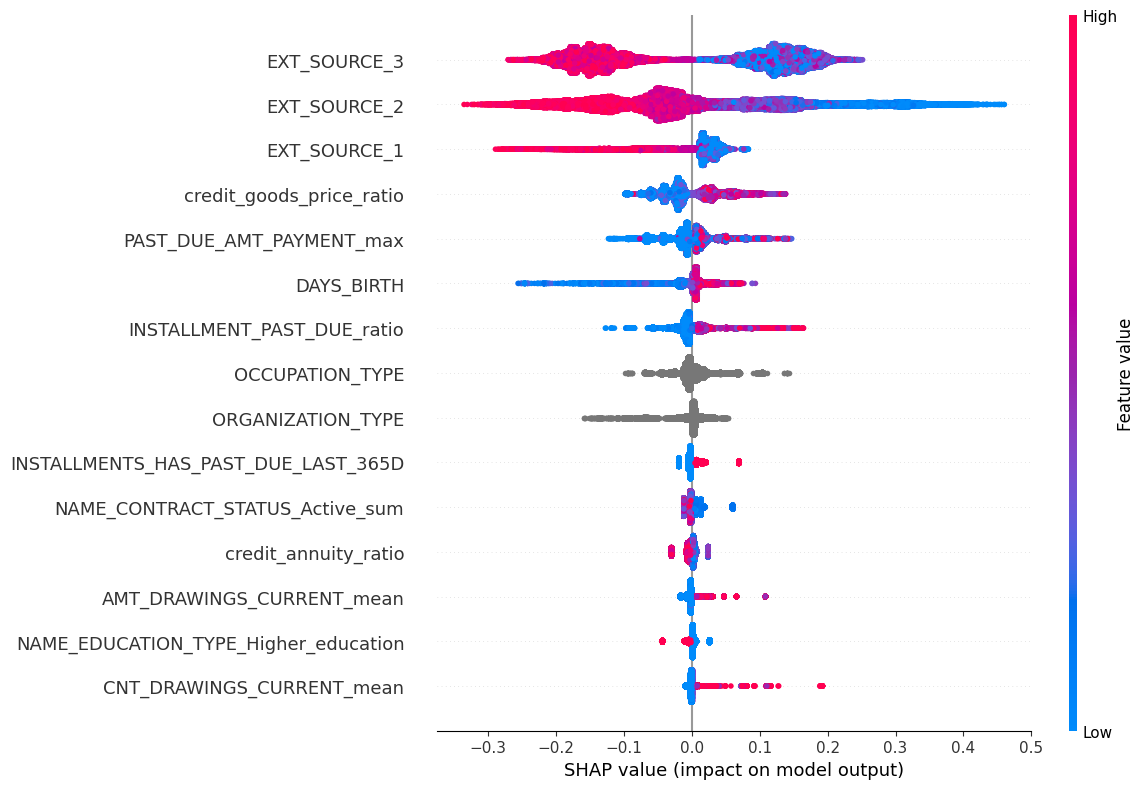

In [28]:
n_shap = min(100000, len(x_tr_pd))
x_shap = x_tr_pd.sample(n=n_shap, random_state=42)

explainer = shap.TreeExplainer(
    lgb_best,
    feature_perturbation="tree_path_dependent"
)

shap_values = explainer.shap_values(x_shap)
shap_values_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(
    shap_values_plot,
    x_shap,
    max_display=15,
    plot_size=(12, 8),
    show=True
)

feature importance & shap value: feature importance is based on information gain, gini.

# Backward Selection

In [29]:
TARGET_METRIC = "roc_auc"     # "roc_auc" for selection
DROP_PER_STEP = 40             # drop 40 feature each iteration
MAX_ITERS = 100 # max rounds the loop can run.
MIN_FEATURES = 10
TOL = 0.01                 # allow tiny drop without caring
SEED = 42

In [30]:
def fit_score(cols):
    model = LGBMClassifier(**grid.best_params_) # ** is the dictionary unpacking operator
    model.fit(x_tr_pd[cols], y_tr_pd)
    proba = model.predict_proba(x_val_pd[cols])[:, 1]
    return model, float(roc_auc_score(y_val_pd, proba))

In [31]:
PERM_SAMPLE_SIZE = 20000
PERM_REPEATS = 1          

n_perm = min(PERM_SAMPLE_SIZE, len(x_val_pd))
x_val_perm = x_val_pd.sample(n=n_perm, random_state=SEED)
y_val_perm = y_val_pd.loc[x_val_perm.index]


# start from all features
cols = list(x_tr_pd.columns)
history = [] # empty list to store selection history

model, best_auc = fit_score(cols) # we defined above
print("Start AUC:", best_auc, "features:", len(cols))

for it in range(1, MAX_ITERS + 1):  # we defined maximum iterations of 20 above.
    # stop if already at minimum feature count
    if len(cols) <= MIN_FEATURES:   # no less than 10 features.
        print("Stop: reached MIN_FEATURES.")
        break

    # permutation importance on sampled validation set
    # keep model fixed, shuffle one feature in vali to see how much AUC dropped.
    perm = permutation_importance(
        estimator=model,
        X=x_val_perm[cols],
        y=y_val_perm,
        scoring="roc_auc",
        n_repeats=PERM_REPEATS,
        random_state=SEED,
        n_jobs=-1
    )

    # build importance table
    imp_df = (
        pl.DataFrame({
            "feature": cols,
            "importance_mean": perm.importances_mean, # avg
            "importance_std": perm.importances_std
        })
        .sort("importance_mean")
    )

    # choose how many to drop this round
    n_drop = min(DROP_PER_STEP, len(cols) - MIN_FEATURES) # we drop 50 features per round for speed
    if n_drop <= 0:
        print("Stop: cannot drop more without going below MIN_FEATURES.")
        break

    drop = imp_df.head(n_drop).get_column("feature").to_list()
    new_cols = [c for c in cols if c not in drop]

    # fit model after dropping weakest features
    new_model, new_auc = fit_score(new_cols) # the new model after dropping redundant features
    delta = new_auc - best_auc
    #---------------------------------------------------------------------------------------------------------
    history.append({ #store a summary of what happened this round
        "iter": it,
        "n_features_before": len(cols),
        "n_dropped": len(drop),
        "dropped": drop,
        "dropped_str": ", ".join(drop),
        "auc": float(new_auc),
        "delta": float(delta),
        "n_features_after": len(new_cols),
    })

    # print a progress message
    print(
        f"Iter {it:02d}: dropped {len(drop)} features "
        f"-> AUC {new_auc:.6f} (Δ {delta:+.6f}) "
        f"features={len(new_cols)}"
    )
    print("Dropped:", drop)

    # accept removal if performance did not worsen too much
    if new_auc >= best_auc - TOL:
        cols = new_cols
        model = new_model
        best_auc = max(best_auc, new_auc)
    else:
        print("Stop: removal hurt beyond tolerance.")
        break

# history output
hist_df = pl.DataFrame(history)

print("\nSelection history:")
print(
    hist_df.select([
        "iter",
        "n_features_before",
        "n_dropped",
        "auc",
        "delta",
        "n_features_after",
        "dropped_str"
    ])
)

print("\nFinal features:", len(cols))
final_features = cols

Start AUC: 0.7692516267092562 features: 691
Iter 01: dropped 40 features -> AUC 0.769033 (Δ -0.000219) features=651
Dropped: ['FLAG_WORK_PHONE', 'PRODUCT_COMBINATION_prev3', 'SELLERPLACE_AREA_prev3', 'INSTALMENT_NUM_4_DAYS_INSTALMENT_mean', 'HOUR_APPR_PROCESS_START_prev1', 'SK_ID_CURR', 'PAST_DUE_NUM_INSTALMENT_NUMBER_max', 'CREDIT_TYPE_Car_loan_sum', 'LIVINGAPARTMENTS_MODE', 'NAME_EDUCATION_TYPE_Incomplete_higher', 'DEF_30_CNT_SOCIAL_CIRCLE', 'NAME_GOODS_CATEGORY_prev1', 'CNT_CREDIT_PROLONG_mean', 'CREDIT_ACTIVE_Closed_sum', 'AMT_DRAWINGS_POS_CURRENT_mean', 'CREDIT_TYPE_Consumer_credit_sum', 'AMT_PAYMENT_TOTAL_CURRENT_max', 'CC_HAS_DPD_DEF_sum', 'APARTMENTS_AVG', 'NUM_INSTALMENT_NUMBER_max', 'DAYS_INSTALMENT_mean', 'AMT_DRAWINGS_POS_CURRENT_max', 'PAST_DUE_PAYMENT_DELAY_DAYS_max', 'FONDKAPREMONT_MODE_reg_oper_spec_account', 'INSTALMENT_NUM_2_DAYS_INSTALMENT_max', 'INSTALMENT_NUM_3_PAYMENT_DELAY_DAYS_mean', 'INSTALMENT_NUM_1_AMT_PAYMENT_max', 'COMMONAREA_MEDI', 'LANDAREA_MEDI', 'SK_ID_

# Save final features

In [32]:
# Columns kept by backward selection
final_features = cols

# Columns removed by backward selection
dropped_features = [c for c in x_tr_pd.columns if c not in final_features]

print("Original feature count:", x_tr_pd.shape[1])
print("Final feature count:", len(final_features))
print("Dropped feature count:", len(dropped_features))

print("\nDropped features:")
print(dropped_features)

# Create reduced datasets
x_tr_selected = x_tr_pd[final_features]
x_val_selected = x_val_pd[final_features]
x_test_selected = x_test_pd[final_features]

print("\nReduced dataset shapes:")
print("x_tr_selected:", x_tr_selected.shape)
print("x_val_selected:", x_val_selected.shape)
print("x_test_selected:", x_test_selected.shape)

Original feature count: 691
Final feature count: 91
Dropped feature count: 600

Dropped features:
['SK_ID_CURR', 'CODE_GENDER_XNA', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_TYPE_SUITE_Children', 'NAME_TYPE_SUITE_Family', 'NAME_TYPE_SUITE_Group_of_people', 'NAME_TYPE_SUITE_Other_A', 'NAME_TYPE_SUITE_Other_B', 'NAME_TYPE_SUITE_Spouse_partner', 'NAME_TYPE_SUITE_Unaccompanied', 'NAME_TYPE_SUITE_null', 'NAME_INCOME_TYPE_Businessman', 'NAME_INCOME_TYPE_Commercial_associate', 'NAME_INCOME_TYPE_Maternity_leave', 'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State_servant', 'NAME_INCOME_TYPE_Student', 'NAME_INCOME_TYPE_Unemployed', 'NAME_EDUCATION_TYPE_Academic_degree', 'NAME_EDUCATION_TYPE_Incomplete_higher', 'NAME_EDUCATION_TYPE_Lower_secondary', 'NAME_FAMILY_STATUS_Civil_marriage', 'NAME_FAMILY_STATUS_Separated', 'NAME_FAMILY_STATUS_Single_not_married', 'NAME_FAMILY_STATUS_Unknown', 'NAME_FAMILY_STATUS_Widow', 'NAME_HOUSING_TYPE_Co_op_apartment', 'NAME_HOUSING_TYPE_Hous

In [33]:
# Save selected feature datasets
x_tr_selected.to_parquet("x_tr_selected.parquet", index=False)
x_val_selected.to_parquet("x_val_selected.parquet", index=False)
x_test_selected.to_parquet("x_test_selected.parquet", index=False)

# Save target variables too
y_tr_pd.to_frame(name="target").to_parquet("y_tr_selected.parquet", index=False)
y_val_pd.to_frame(name="target").to_parquet("y_val_selected.parquet", index=False)
y_test_pd.to_frame(name="target").to_parquet("y_test_selected.parquet", index=False)

# Save feature lists
pl.DataFrame({"feature": final_features}).write_csv("final_features.csv")
pl.DataFrame({"feature": dropped_features}).write_csv("dropped_features.csv")

print("Saved selected datasets and feature lists.")

Saved selected datasets and feature lists.


In [34]:
x_tr_selected = pl.read_parquet("x_tr_selected.parquet").to_pandas()
x_val_selected = pl.read_parquet("x_val_selected.parquet").to_pandas()
x_test_selected = pl.read_parquet("x_test_selected.parquet").to_pandas()

y_tr_pd = pl.read_parquet("y_tr_selected.parquet").to_pandas().iloc[:, 0]
y_val_pd = pl.read_parquet("y_val_selected.parquet").to_pandas().iloc[:, 0]
y_test_pd = pl.read_parquet("y_test_selected.parquet").to_pandas().iloc[:, 0]

final_features = pl.read_csv("final_features.csv")["feature"].to_list()
dropped_features = pl.read_csv("dropped_features.csv")["feature"].to_list()

In [35]:
# Save final kept features and dropped features to Desktop
SAVE_PATH = "/Users/alexzhang/Desktop"

pl.DataFrame({
    "feature": final_features
}).write_csv(f"{SAVE_PATH}/final_features.csv")

pl.DataFrame({
    "feature": dropped_features
}).write_csv(f"{SAVE_PATH}/dropped_features.csv")

print("Saved feature files:")
print(f"{SAVE_PATH}/final_features.csv")
print(f"{SAVE_PATH}/dropped_features.csv")

Saved feature files:
/Users/alexzhang/Desktop/final_features.csv
/Users/alexzhang/Desktop/dropped_features.csv


# Run saved features

In [36]:
SAVE_PATH = "/Users/alexzhang/Desktop"

final_features = pl.read_csv(f"{SAVE_PATH}/final_features.csv")["feature"].to_list()
dropped_features = pl.read_csv(f"{SAVE_PATH}/dropped_features.csv")["feature"].to_list()

print("Loaded final features:", len(final_features))
print("Loaded dropped features:", len(dropped_features))

Loaded final features: 91
Loaded dropped features: 600


In [37]:
def get_kept_prevapp_base_cols(final_features):
    """
    From selected features like:
        AMT_CREDIT_prev1
        AMT_CREDIT_prev2
        NAME_CONTRACT_STATUS_prev3

    recover base columns:
        AMT_CREDIT
        NAME_CONTRACT_STATUS

    Exclude ID columns from model features.
    """

    kept_base_cols = set()

    for feature in final_features:
        if re.search(r"_prev[123]$", feature):
            base_col = re.sub(r"_prev[123]$", "", feature)

            # Do not bring ID columns back as model features
            if base_col not in ["SK_ID_CURR", "SK_ID_PREV"]:
                kept_base_cols.add(base_col)

    return sorted(kept_base_cols)